# BRFSS 2015 Diabetes Health Indicators — Risk and Outreach Models (Optuna TPE variant)

> This is a copy of `WolfgangKlein.ipynb` that tunes Bagged GLMnet, Random forest and XGBoost
> with Optuna's TPE sampler instead of random search (§5). Everything else is unchanged. Its
> sweeps live in `cache/lab3_optuna/`, so the two notebooks never share or overwrite results.

**Authors:** Wolfgang Klein, Sydney Bailey, Harvey Luna, Nashita Khandaker
**Data:** `diabetes_012_health_indicators_BRFSS2015.csv` (253,680 respondents), target
collapsed to binary as in Labs 1 and 2 (prediabetes and diabetes both coded 1)

## 1. The problem

[Lab 1](https://lone-wolfgang.github.io/brfss2015-diabetes-eda/#Lab1/WolfgangKlein) §11
found that the target records a *diagnosis*, and that a diagnosis depends on contact with a
doctor. Respondents who had not had a cholesterol check in five years carried only 39% of
the diagnoses their risk profiles predicted. Finding people at risk is therefore only half
of a screening programme. The other half is finding the people the health system is not
reaching.

This notebook builds a pair of models, one for each half.

- **Task 1: diabetes risk.** Who is likely to have diabetes or prediabetes? The model scores
  each respondent's clinical and lifestyle profile.
- **Task 2: outreach.** Who is likely *not* to have been screened? These respondents are the
  target for outreach, because a high-risk person who never sees a doctor will not be
  diagnosed however good the risk model is.

A respondent who scores high on both is the person a screening programme most needs to
reach. Each task is solved with the same pipeline: six model families, each tuned by
5-fold cross-validation, a stacked ensemble of all six, and a decision threshold tuned on a
separate validation set.

**Metric.** As in [Lab 2](https://lone-wolfgang.github.io/brfss2015-diabetes-eda/#Lab2/WolfgangKlein),
the models are compared on **F2**, which weights recall four times as heavily as precision.
In both tasks a missed case costs more than a wasted contact: a missed diagnosis lets a
progressive disease go untreated, and a missed outreach target stays unscreened, while an
unnecessary referral or phone call is cheap by comparison.

$$
F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}}
$$

F2 depends on a threshold, so it is not used for tuning. Hyperparameters are chosen on
**average precision** (AP, the area under the precision–recall curve), which scores the
ranking across all thresholds and, unlike ROC-AUC, is sensitive to how well the rare class
is ranked. The threshold is then chosen for F2 on the validation set (§7).

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json, os, time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost
from scipy.stats import loguniform, uniform, randint

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_predict)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             precision_score, recall_score, fbeta_score, confusion_matrix)
from xgboost import XGBClassifier
import optuna
from optuna.samplers import TPESampler

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

PALETTE = {
    "ink":    "#22303c",
    "grid":   "#dfe4e8",
    "neg":    "#8fa3b0",   # reference / unexposed
    "pos":    "#b5442e",   # diabetes / elevated
    "prot":   "#2f6f6a",   # protective direction
    "accent": "#c98a1b",
    "best":   "#0a6cff",   # selected candidate in parallel-coordinates plots
}
SEQ = sns.blend_palette(["#f5f2ea", "#d8b26a", "#b5442e", "#5c1d13"], as_cmap=True)

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "axes.edgecolor": PALETTE["grid"],
    "axes.grid": True, "grid.color": PALETTE["grid"], "grid.linewidth": 0.7,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": PALETTE["ink"], "axes.labelcolor": PALETTE["ink"],
    "xtick.color": PALETTE["ink"], "ytick.color": PALETTE["ink"],
    "legend.frameon": False, "figure.facecolor": "white",
})

SEED    = 0
N_FOLDS = 5
N_JOBS  = -1          # all cores; every model below is single-threaded so the folds run in parallel
CACHE   = Path("cache/lab3_optuna")
CACHE.mkdir(parents=True, exist_ok=True)
# TPE sweeps are Optuna studies in one SQLite file. The heartbeat marks trials orphaned by an
# interrupted kernel as failed, so a rerun resumes cleanly.
STUDIES     = optuna.storages.RDBStorage(f"sqlite:///{CACHE / 'studies.db'}", heartbeat_interval=60)
TPE_STARTUP = 32      # random trials before TPE starts guiding the search
TPE_JOBS    = 2       # trials run at once, each with its 5 folds in parallel (10 cores busy)
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| optuna", optuna.__version__, "| cores", os.cpu_count())

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.9.0 | xgboost 3.4.1 | optuna 5.0.0 | cores 14


In [2]:
PATH = "../data/diabetes_012_health_indicators_BRFSS2015.csv"
assert os.path.exists(PATH), f"Dataset not found at {PATH}. See README for setup."

raw = pd.read_csv(PATH)
raw["Diabetes_binary"] = (raw["Diabetes_012"] > 0).astype(int)
raw = raw.drop(columns="Diabetes_012")
raw["NoCheck"] = (1 - raw["CholCheck"]).astype(int)      # Task 2 outcome: no cholesterol check in 5 years

print(f"shape : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Diabetes_binary prevalence : {100*raw.Diabetes_binary.mean():.2f}%")
print(f"NoCheck prevalence         : {100*raw.NoCheck.mean():.2f}%")

shape : 253,680 rows x 23 columns
Diabetes_binary prevalence : 15.76%
NoCheck prevalence         : 3.73%


## 2. Variables

Each column of the file has one role in each task: the **outcome**, a **feature** the model
may use, or **withheld** because using it would teach the model the wrong thing.

**Task 1** predicts `Diabetes_binary` from the 18 features that do not describe access to
care. Lab 1 §11 showed that `CholCheck`, `AnyHealthcare` and `NoDocbcCost` measure whether
the outcome *could* be observed, not whether the disease is present. A model given them
learns that people who never see a doctor are never diagnosed, and would rank the
unscreened as low-risk for exactly the wrong reason. (Lab 2 dropped only `CholCheck`; this
lab drops all three.) The comorbidities stay in. They are strong evidence that diabetes is
already present, which is what the risk model is looking for.

**Task 2** predicts `NoCheck`, which is `CholCheck` reversed: 1 means no cholesterol check
in the past five years. It is the variable Lab 1 used to define "screened", so the two
tasks use the same definition. The two coverage columns move from withheld to features,
because lacking insurance or being unable to afford a doctor are plausible *causes* of
missed screening. The five "ever told" diagnoses (`HighBP`, `HighChol`,
`HeartDiseaseorAttack`, `Stroke` and `Diabetes_binary` itself) are withheld for the
opposite reason: each one is the *result* of a doctor's visit. Nobody is told their
cholesterol is high without a cholesterol test, so `HighChol` would hand the model the
answer. The cell below shows how strongly each diagnosis tracks the outcome.

`DiffWalk` is the exception among the conditions. It is a self-reported functional
limitation, not a diagnosis, so it stays in Task 2.

In [3]:
ACCESS = ["CholCheck", "AnyHealthcare", "NoDocbcCost"]
TOLD   = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]
BASE   = ["HighBP", "HighChol", "BMI", "Smoker", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
          "Fruits", "Veggies", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "GenHlth",
          "MentHlth", "PhysHlth", "DiffWalk", "Sex", "Age", "Education", "Income"]
ENGINEERED = ["Age_sq", "Income_sq"]          # added in §3

T1_FEATURES = [c for c in BASE if c not in ACCESS] + ENGINEERED
T2_FEATURES = [c for c in BASE if c not in TOLD] + ENGINEERED

def role(col, features, outcome, withheld_reason):
    if col == outcome:   return "outcome"
    if col in features:  return "feature"
    return f"withheld: {withheld_reason.get(col, '')}"

R1 = {c: "access, not disease" for c in ACCESS} | {"NoCheck": "access, not disease"}
R2 = {c: "result of a doctor's visit" for c in TOLD + ["Diabetes_binary"]}
cols = ["Diabetes_binary", "NoCheck", "CholCheck"] + [c for c in BASE if c not in ("CholCheck",)] + ENGINEERED
roles = pd.DataFrame({
    "Task 1: diabetes risk": [role(c, T1_FEATURES, "Diabetes_binary", R1) for c in cols],
    "Task 2: outreach":      [role(c, T2_FEATURES, "NoCheck", R2) for c in cols],
}, index=pd.Index(cols, name="variable"))
roles.loc["CholCheck", "Task 2: outreach"] = "outcome (as NoCheck)"
roles.loc["NoCheck", "Task 1: diabetes risk"] = "withheld: access, not disease"
display(roles)
print(f"Task 1: {len(T1_FEATURES)} features   Task 2: {len(T2_FEATURES)} features")

,Task 1: diabetes risk,Task 2: outreach
variable,,
Diabetes_binary,outcome,withheld: result of a doctor's visit
NoCheck,"withheld: access, not disease",outcome
CholCheck,"withheld: access, not disease",outcome (as NoCheck)
HighBP,feature,withheld: result of a doctor's visit
HighChol,feature,withheld: result of a doctor's visit
BMI,feature,feature
Smoker,feature,feature
Stroke,feature,withheld: result of a doctor's visit
HeartDiseaseorAttack,feature,withheld: result of a doctor's visit


Task 1: 20 features   Task 2: 18 features


In [4]:
told = pd.DataFrame({
    "% told, checked in 5 yrs":     100 * raw.loc[raw.CholCheck == 1, TOLD + ["Diabetes_binary"]].mean(),
    "% told, not checked in 5 yrs": 100 * raw.loc[raw.CholCheck == 0, TOLD + ["Diabetes_binary"]].mean(),
})
told["ratio"] = told.iloc[:, 0] / told.iloc[:, 1]
display(told.round(2))

,"% told, checked in 5 yrs","% told, not checked in 5 yrs",ratio
HighBP,43.8600,18.1400,2.4200
HighChol,43.2500,20.9200,2.0700
HeartDiseaseorAttack,9.6700,2.8600,3.3800
Stroke,4.1500,1.6400,2.5400
Diabetes_binary,16.2500,3.2000,5.0800


Every diagnosis is far more common among respondents who had a cholesterol check. High
cholesterol is reported about twice as often (43.2% against 20.9%), and high blood pressure,
heart disease and stroke show gaps of a similar size. Part of each gap is real, since sicker
people see doctors more, but part of it is mechanical: the diagnosis exists only because of
the visit. A Task 2 model given these columns would learn "has been diagnosed, therefore has
been seen", which predicts screening without explaining it.

## 3. Data preparation

**BMI is winsorized at 70.** Lab 1 §2.3 showed that above 70 the variable stops recording a
measurement (odd values are about ten times as common as even ones). Capping at 70 keeps
those 584 rows without letting them drive the linear models.

**Age and income get centered squared terms.** Both curves bend (Lab 1 §6), and Lab 2 found
the squared terms worthwhile in a linear model. The tree models ignore them.

**Duplicate rows are kept.** Lab 1 §3 showed that they are distinct, mostly healthy people
who answered the questionnaire identically. Dropping them would shift both base rates.

**Rows that would dilute each outcome are withheld.**

- **Task 1 is trained on screened respondents only.** A never-screened respondent coded 0 may
  well have undiagnosed diabetes (Lab 1 §11 estimated that 482 of them do). Their negative
  labels are not credible, and training on them would teach the model that a risky profile
  without a diagnosis is safe. The 9,470 never-screened respondents are set aside.
- **Task 2 is trained on undiagnosed respondents only.** A diabetes diagnosis brings regular
  lipid panels with it, so diagnosed respondents are screened *because* they are diagnosed.
  They would teach the model the reverse arrow, and they are not outreach targets in any
  case: they are already in care. The 39,977 diagnosed respondents are set aside.

In [5]:
df = raw.copy()
df["BMI"] = np.minimum(df["BMI"], 70)
for col in ["Age", "Income"]:
    df[f"{col}_sq"] = (df[col] - df[col].mean()) ** 2

TASKS = {
    "T1": dict(title="Task 1: diabetes risk", outcome="Diabetes_binary", features=T1_FEATURES,
               rows=df.CholCheck.eq(1), withheld="never screened (CholCheck = 0)",
               labels=("no diabetes", "diabetes")),
    "T2": dict(title="Task 2: outreach", outcome="NoCheck", features=T2_FEATURES,
               rows=df.Diabetes_binary.eq(0), withheld="already diagnosed (Diabetes_binary = 1)",
               labels=("screened", "not screened")),
}
for t in TASKS.values():
    d = df.loc[t["rows"]]
    t["X"], t["y"] = d[t["features"]].astype(float), d[t["outcome"]].astype(int)

balance = pd.DataFrame({
    "rows kept":     [len(t["y"]) for t in TASKS.values()],
    "rows withheld": [int((~t["rows"]).sum()) for t in TASKS.values()],
    "withheld":      [t["withheld"] for t in TASKS.values()],
    "positives":     [int(t["y"].sum()) for t in TASKS.values()],
    "positive %":    [100 * t["y"].mean() for t in TASKS.values()],
    "negatives per positive": [(1 - t["y"].mean()) / t["y"].mean() for t in TASKS.values()],
}, index=[t["title"] for t in TASKS.values()])
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(balance)

,rows kept,rows withheld,withheld,positives,positive %,negatives per positive
Task 1: diabetes risk,244210,9470,never screened (CholCheck = 0),39674,16.25,5.16
Task 2: outreach,213703,39977,already diagnosed (Diabetes_binary = 1),9167,4.29,22.31


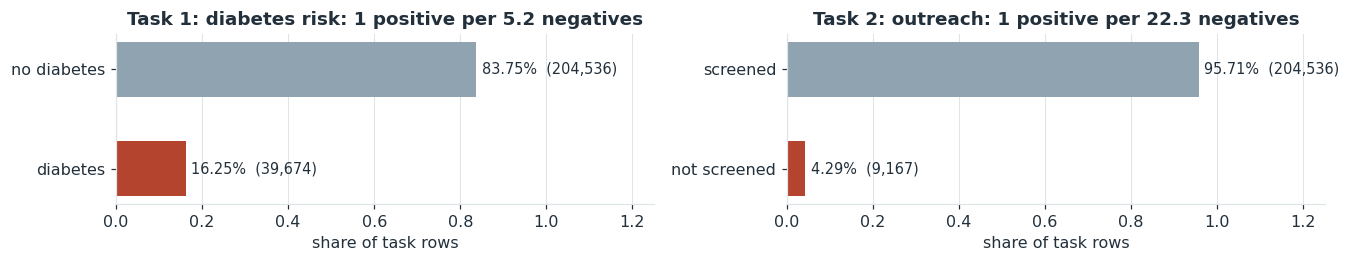

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.5))
for ax, t in zip(axes, TASKS.values()):
    p = t["y"].mean()
    ax.barh([t["labels"][1], t["labels"][0]], [p, 1 - p], color=[PALETTE["pos"], PALETTE["neg"]], height=.55)
    for i, v in enumerate([p, 1 - p]):
        ax.text(v + .012, i, f"{100*v:.2f}%  ({int(round(v*len(t['y']))):,})", va="center", fontsize=9.5)
    ax.set_xlim(0, 1.25); ax.set_xlabel("share of task rows"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{t['title']}: 1 positive per {(1-p)/p:.1f} negatives")
plt.tight_layout(); plt.show()

The two tasks have very different balance. Task 1 has about one positive for every five
negatives (16.25%), similar to the full file. Task 2 is rare: about 4.3% of undiagnosed
respondents have had no cholesterol check, about one in 23. A model that never flags anyone
scores 95.7% accuracy on Task 2, which is why every model is tuned on AP and judged on F2,
and why class weighting is part of every sweep.

## 4. Splitting strategy

Each task is split 70 / 15 / 15, stratified on the outcome.

- **train (70%)**: fits every model and tunes its hyperparameters by 5-fold cross-validation.
- **validation (15%)**: chooses each model's decision threshold (§7) and nothing else.
- **test (15%)**: touched once, for the final scores in §8.

In [7]:
for t in TASKS.values():
    X_tr, X_rest, y_tr, y_rest = train_test_split(t["X"], t["y"], train_size=0.70,
                                                  stratify=t["y"], random_state=SEED)
    X_va, X_te, y_va, y_te = train_test_split(X_rest, y_rest, test_size=0.5,
                                              stratify=y_rest, random_state=SEED)
    t.update(X_train=X_tr, y_train=y_tr, X_val=X_va, y_val=y_va, X_test=X_te, y_test=y_te)

splits = pd.DataFrame([
    {"task": t["title"], "split": s, "rows": len(t[f"y_{s}"]),
     "share %": 100 * len(t[f"y_{s}"]) / len(t["y"]),
     "positives": int(t[f"y_{s}"].sum()), "positive %": 100 * t[f"y_{s}"].mean()}
    for t in TASKS.values() for s in ("train", "val", "test")]).set_index(["task", "split"])
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(splits)

rows  share %  positives  positive %
task                  split                                        
Task 1: diabetes risk train  170947    70.00      27772       16.25
                      val     36631    15.00       5951       16.25
                      test    36632    15.00       5951       16.25
Task 2: outreach      train  149592    70.00       6417        4.29
                      val     32055    15.00       1375        4.29
                      test    32056    15.00       1375        4.29

## 5. Models

Six model families are tuned for each task.

| model | what it adds | tuned |
|---|---|---|
| **Logistic regression** | the interpretable baseline from Lab 2 | `C`, L1 vs L2, class weights |
| **Bagged GLMnet** | elastic-net logistic regression averaged over bootstrap samples, which steadies the coefficients | `C`, L1 share, class weights, bag size, sample share |
| **Linear SVM** | a margin-based linear boundary (Lab 2's kernel screen found no gain from non-linear kernels) | `C`, L1 vs L2, class weights |
| **Decision tree** | non-linear and readable, but unstable | depth, leaf size, split criterion, class weights |
| **Random forest** | many decorrelated trees, averaged | trees, depth, leaf size, features per split, sample share, class weights |
| **XGBoost** | gradient-boosted trees, usually the strongest on tabular data | trees, learning rate, depth, child weight, row and column sampling, L2 penalty, positive-class weight |

The three linear models see standardized features. The tree models see the raw values.

**Sweeps.** Every candidate is scored by stratified 5-fold cross-validation on `train`
alone, so neither validation nor test plays any part. The three linear models and the
decision tree fit in seconds, so they get a full grid. The bagged GLMnet, random forest and
XGBoost take longer per fit and have more hyperparameters, so they get a randomized search.
Candidates are ranked on mean CV AP; ROC-AUC is recorded alongside.

Each sweep is run in two steps, one helper cell each.

### Experiment

`experiment()` runs one sweep for one task. It takes the task, the model and its search
space, scores every candidate by 5-fold cross-validation on `train`, and saves the results. A
grid or random search is saved to `cache/lab3_optuna/<task>_<model>.joblib`; a TPE search is
an Optuna study in `cache/lab3_optuna/studies.db`, saved after every trial. It then refits the best candidate on all of `train`, ready
for §6–8.

If the cache already holds a sweep of the same search space, it is read back instead of
rerun. Changing a space reruns that sweep; deleting the folder reruns everything. A TPE study is named
after its task, model and a hash of its search space, so an interrupted sweep resumes where it
stopped and a changed space starts a new study.

**TPE (tree-structured Parzen estimator).** The first 32 trials are drawn at random. After that,
each new candidate is drawn where the good trials so far are dense and the poor ones sparse, so
more of the budget is spent near the best region. Two trials run at a time; Optuna's
"constant liar" counts a running trial as a poor one so the two do not pick the same spot.

*Caveats.* With 256 trials over five to eight hyperparameters, random search already gets close,
so TPE's gain in CV AP is expected to be small, often inside the fold-to-fold spread (`AP sd`).
Trials partly wait on each other, so a sweep takes longer than random search on all cores. Two
trials run at once, so the trial order (and with it the exact result) can differ between runs.

In [8]:
import hashlib, sys
from sklearn.model_selection import cross_validate
from tqdm.std import tqdm             # plain-text bar; ipywidgets is not installed

CV      = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
SCORING = {"AP": "average_precision", "AUC": "roc_auc"}
MODELS  = {}          # MODELS[task][model] = best candidate, refit on all of train
META    = ("CV AP", "AP sd", "CV AUC", "fit s", "selected")      # sweep-table columns that are not hyperparameters


def cache_path(task, name):
    return CACHE / f"{task}_{name.replace(' ', '_')}.joblib"


def space_spec(space, n_iter):
    """A stable text description of a search space, stored with its cache so a changed space is rerun."""
    def one(v):
        if hasattr(v, "dist"):                                  # frozen scipy distribution
            return f"{v.dist.name}{tuple(float(a) for a in v.args)}"
        return repr([None if u is None else (u if isinstance(u, str) else float(u)) for u in v])
    return repr({k: one(v) for k, v in sorted(space.items())}) + f" n_iter={n_iter}"


def suggest(trial, space):
    """Draw one candidate from a search space written for scikit-learn's searches."""
    p = {}
    for k, v in space.items():
        if hasattr(v, "dist"):                                  # frozen scipy distribution
            a = [float(x) for x in v.args]
            if v.dist.name == "loguniform":
                p[k] = trial.suggest_float(k, a[0], a[1], log=True)
            elif v.dist.name == "uniform":                      # scipy's uniform(loc, scale) spans [loc, loc + scale]
                p[k] = trial.suggest_float(k, a[0], a[0] + a[1])
            elif v.dist.name == "randint":                      # scipy's randint excludes its upper bound
                p[k] = trial.suggest_int(k, int(a[0]), int(a[1]) - 1)
            else:
                raise ValueError(f"no Optuna equivalent for {v.dist.name}")
        else:
            p[k] = trial.suggest_categorical(k, [u.item() if isinstance(u, np.generic) else u for u in v])
    return p


def study_results(study, spec):
    """The completed trials of a study, in the same form as a cached grid or random search."""
    done = study.get_trials(deepcopy=False, states=[optuna.trial.TrialState.COMPLETE])
    attr = lambda k: np.array([tr.user_attrs[k] for tr in done])
    return dict(params=[tr.params for tr in done], AP=np.array([tr.value for tr in done]),
                AP_sd=attr("AP_sd"), AUC=attr("AUC"), fit_s=attr("fit_s"),
                wall_s=(max(tr.datetime_complete for tr in done) - min(tr.datetime_start for tr in done)).total_seconds(),
                spec=spec)


def tpe_search(task, name, estimator, space, n_iter, X, spec):
    """Run (or resume) a TPE study until it holds n_iter completed trials."""
    y = TASKS[task]["y_train"]
    study = optuna.create_study(
        storage=STUDIES, load_if_exists=True, direction="maximize",
        study_name=f"{task}_{name.replace(' ', '_')}_{hashlib.md5(spec.encode()).hexdigest()[:12]}",
        sampler=TPESampler(seed=SEED, multivariate=True, n_startup_trials=TPE_STARTUP))

    def objective(trial):
        cv = cross_validate(clone(estimator).set_params(**suggest(trial, space)), X, y, cv=CV,
                            scoring=SCORING, n_jobs=N_FOLDS, error_score="raise")
        trial.set_user_attr("AP_sd", float(cv["test_AP"].std()))
        trial.set_user_attr("AUC", float(cv["test_AUC"].mean()))
        trial.set_user_attr("fit_s", float(cv["fit_time"].mean()))
        return float(cv["test_AP"].mean())

    done = len(study.get_trials(deepcopy=False, states=[optuna.trial.TrialState.COMPLETE]))
    if done < n_iter:
        bar = tqdm(total=n_iter, initial=done, desc=f"{task} {name}", unit="trial", file=sys.stdout,
                   dynamic_ncols=True, smoothing=0.1)

        def tick(study, trial):
            if trial.state == optuna.trial.TrialState.COMPLETE:
                bar.update(1)
                bar.set_postfix(best_AP=f"{study.best_value:.4f}")

        try:
            study.optimize(objective, n_trials=n_iter - done, n_jobs=TPE_JOBS, callbacks=[tick])
        finally:
            bar.close()
    return study_results(study, spec)


SWEEPS = {}           # SWEEPS[(task, model)] = the sweep experiment() last ran or read, for report()


def experiment(task, name, estimator, space, n_iter=None, X=None, tag="", sampler="random"):
    """Run (or read back) one 5-fold CV sweep on train, cache it, and refit the best candidate.

    n_iter=None runs the full grid; a number draws that many candidates, at random or, with
    sampler="tpe", by Optuna's TPE sampler (stored as a study in cache/lab3_optuna/studies.db).
    X replaces the task's training features (the ensemble passes its stacked inputs);
    tag is added to the cache key so a change in those inputs also forces a rerun.
    """
    t = TASKS[task]
    X = t["X_train"] if X is None else X
    path, spec = cache_path(task, name), space_spec(space, n_iter) + tag
    if sampler == "tpe":
        res = tpe_search(task, name, estimator, space, n_iter, X, space_spec(space, None) + tag + " sampler=tpe")
    else:
        res = joblib.load(path) if path.exists() else None
    if sampler != "tpe" and (res is None or res.get("spec") != spec):
        kw = dict(cv=CV, scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise")
        search = (GridSearchCV(estimator, space, **kw) if n_iter is None else
                  RandomizedSearchCV(estimator, space, n_iter=n_iter, random_state=SEED, **kw))
        t0 = time.perf_counter()
        search.fit(X, t["y_train"])
        cv = search.cv_results_
        res = dict(params=cv["params"], AP=cv["mean_test_AP"], AP_sd=cv["std_test_AP"],
                   AUC=cv["mean_test_AUC"], fit_s=cv["mean_fit_time"], wall_s=time.perf_counter() - t0,
                   spec=spec)
        joblib.dump(res, path)

    SWEEPS[(task, name)] = res
    best = int(np.argmax(res["AP"]))
    model = clone(estimator).set_params(**res["params"][best]).fit(X, t["y_train"])
    MODELS.setdefault(task, {})[name] = model
    print(f"{t['title']:<24} {name:<20} {len(res['params']):3d} candidates x {N_FOLDS} folds {sampler:<6} "
          f"({res['wall_s']/60:4.1f} min)   best CV AP {res['AP'][best]:.4f}  AUC {res['AUC'][best]:.4f}")
    return model


def scores(model, X):
    """Probability of the positive class, or the SVM's signed distance from its boundary."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

### Report

`report()` reads a model's two sweeps back (from `cache/lab3_optuna/`, or the study for a TPE search) and shows them side by
side: a parallel-coordinates plot for each task, then a table of the winning settings.

**Reading the plot.** Each line is one candidate. It crosses one axis per hyperparameter at
the value it tried and ends on the right at its CV AP. Lines are coloured by score, darkest
best. The selected candidate is the bold line, with its value printed beside every axis.

- A hyperparameter that matters shows the dark lines bunched on one part of its axis. One
  that does not shows dark and light lines crossing it everywhere.
- An axis with a dozen or fewer values has one tick per value tried. A continuous range is
  drawn to scale (logarithmic when it spans more than a factor of 20), and its end ticks are
  the smallest and largest values sampled.
- A winner at the end of an axis suggests the range may be too narrow.
- For a TPE search the lines bunch near the best region by design, so a bunched axis there
  shows where TPE spent its trials as well as what matters. The 32 random start-up trials
  are the ones spread evenly.

In [9]:
NONE_LABEL = {"max_depth": "unlimited", "class_weight": "none"}     # what None means for each hyperparameter


def _is_none(u):
    return u is None or (isinstance(u, float) and np.isnan(u))


def _label(name, u):
    """One hyperparameter value as printed on the plots and tables."""
    if _is_none(u):
        return NONE_LABEL.get(name, "none")
    if isinstance(u, (int, float, np.number)):
        return f"{u:g}" if float(u) == round(float(u)) else f"{u:.3g}"
    return str(u)


def _round_ticks(lo, hi, logscale):
    """Round values inside [lo, hi] (axis units): 1-2-5 per decade on a log axis, about five on a linear one."""
    if logscale:
        t = [np.log10(m) + e for e in range(int(np.floor(lo)), int(np.ceil(hi)) + 1) for m in (1, 2, 5)]
        t = [z for z in t if lo - 1e-9 <= z <= hi + 1e-9]
        if len(t) > 7:
            t = [z for z in t if abs(z - round(z)) < 1e-9]      # whole decades only
        if len(t) > 7:
            t = t[::2]
        return t
    return [z for z in mpl.ticker.MaxNLocator(5).tick_values(lo, hi) if lo - 1e-9 <= z <= hi + 1e-9]


def _axis(name, values):
    """Map one hyperparameter column onto [0, 1]; return positions, tick positions, tick labels."""
    v = pd.Series(list(values), dtype=object)
    num = pd.to_numeric(v, errors="coerce")
    if num.notna().all() and v.nunique() > 12:                  # continuous draw or long grid: a numeric scale
        x = num.astype(float)
        logscale = x.min() > 0 and x.max() / x.min() > 20
        z = np.log10(x) if logscale else x
        lo, hi = z.min(), z.max()
        span = hi - lo if hi > lo else 1.0
        inner = [u for u in _round_ticks(lo, hi, logscale) if min(u - lo, hi - u) > .08 * span]
        tz = [lo] + inner + [hi]                                # the ends are the extreme values tried
        return (((z - lo) / span).to_numpy(), [(u - lo) / span for u in tz],
                [_label(name, 10 ** u if logscale else u) for u in tz])
    lab = v.map(lambda u: _label(name, u))                       # a few values: one tick each, evenly spaced
    first = dict(zip(lab, v))
    def rank(s):                                                # numbers by value, then words, then None
        u = first[s]
        if _is_none(u):
            return (2, 0.0, s)
        return (0, float(u), "") if isinstance(u, (int, float, np.number)) else (1, 0.0, s)
    order = sorted(lab.unique(), key=rank)
    p = {s: (i / (len(order) - 1) if len(order) > 1 else .5) for i, s in enumerate(order)}
    return lab.map(p).to_numpy(float), list(p.values()), order


def load_sweep(task, name):
    """One cached sweep as a table: a row per candidate, its hyperparameters and scores."""
    res = SWEEPS.get((task, name)) or joblib.load(cache_path(task, name))     # TPE sweeps exist only as studies
    table = pd.DataFrame([{short(k): v for k, v in p.items()} for p in res["params"]])
    table["CV AP"], table["AP sd"], table["CV AUC"], table["fit s"] = res["AP"], res["AP_sd"], res["AUC"], res["fit_s"]
    table["selected"] = table.index == int(np.argmax(res["AP"]))
    return table


def short(p):
    """'baggingclassifier__estimator__C' -> 'C'"""
    return p.split("__")[-1]


def parcoords(ax, table, title):
    params = [c for c in table.columns if c not in META and table[c].astype(object).nunique(dropna=False) > 1]
    cols = params + ["CV AP"]
    axes = {c: _axis(c, table[c]) for c in cols}
    P = np.column_stack([axes[c][0] for c in cols])
    s = table["CV AP"].to_numpy()
    lo = np.percentile(s, 10)                                   # keep failed candidates from washing out the scale
    norm = mpl.colors.Normalize(vmin=lo, vmax=s.max())
    xs = np.arange(len(cols))
    for i in np.argsort(s):                                     # best drawn last, on top
        if table["selected"].iloc[i]:
            continue
        ax.plot(xs, P[i], color=SEQ(norm(max(s[i], lo))), lw=1.1, alpha=.85)
    b = int(np.flatnonzero(table["selected"])[0])
    ax.plot(xs, P[b], color="white", lw=6.5, solid_capstyle="round", zorder=5)      # halo so it lifts off the dark lines
    ax.plot(xs, P[b], color=PALETTE["best"], lw=4, solid_capstyle="round", zorder=6)
    for j, c in enumerate(cols):
        _, tp, tl = axes[c]
        ax.axvline(j, color=PALETTE["neg"], lw=.8, zorder=0)
        for p, l in zip(tp, tl):
            ax.text(j - .04, p, l, ha="right", va="center", fontsize=7.6, color=PALETTE["ink"])
        sel = f"{s[b]:.4f}" if c == "CV AP" else _label(c, table[c].iloc[b])
        ax.text(j + .06, P[b, j], sel, ha="left", va="center", fontsize=7.8, fontweight="bold",
                color=PALETTE["best"], zorder=7, bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none", alpha=.9))
    ax.set_xticks(xs, cols, rotation=20, ha="right", fontsize=8.8)
    ax.set_yticks([]); ax.set_ylim(-.06, 1.06); ax.set_xlim(-.6, len(cols) - .35)
    ax.grid(visible=False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(f"{title}\nselected: CV AP {s[b]:.4f} (bold blue line, values in blue)", fontsize=11)
    return norm


def report(name):
    """Parallel coordinates for one model, both tasks, then the selected settings."""
    tables = {key: load_sweep(key, name) for key in TASKS}
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.6))
    for ax, (key, t) in zip(axes, TASKS.items()):
        norm = parcoords(ax, tables[key], f"{t['title']}: {name}")
        cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=SEQ), ax=ax, fraction=.025, pad=.01)
        cb.set_label("CV AP", fontsize=9); cb.ax.tick_params(labelsize=8)
    plt.tight_layout(); plt.show()
    rows = {}
    for key, t in TASKS.items():
        tb = tables[key]
        best = tb.loc[tb["selected"]].iloc[0]
        rows[t["title"]] = {**{c: _label(c, best[c]) for c in tb.columns if c not in META},
                            **{c: f"{best[c]:.4f}" for c in ("CV AP", "AP sd", "CV AUC")},
                            "fit s": f"{best['fit s']:.1f}", "candidates": len(tb)}
    display(pd.DataFrame(rows).T)

### 5.1 Logistic regression

A full grid of 76 candidates, fit with the `liblinear` solver.

- **`C`** (1e-5 to 1e4, 19 values): the inverse of the penalty strength. Small values shrink
  the coefficients hard; large values leave the fit almost unpenalized.
- **`l1_ratio`** (0 or 1): the type of penalty. 0 is L2, which shrinks all coefficients
  together; 1 is L1, which can set weak features to exactly zero. (scikit-learn 1.8 sets the
  penalty this way.)
- **`class_weight`** (none or balanced): whether errors on the rare class count extra during
  fitting.

Task 1: diabetes risk    Logistic regression   76 candidates x 5 folds random ( 0.2 min)   best CV AP 0.4420  AUC 0.8152
Task 2: outreach         Logistic regression   76 candidates x 5 folds random ( 0.1 min)   best CV AP 0.1064  AUC 0.6900


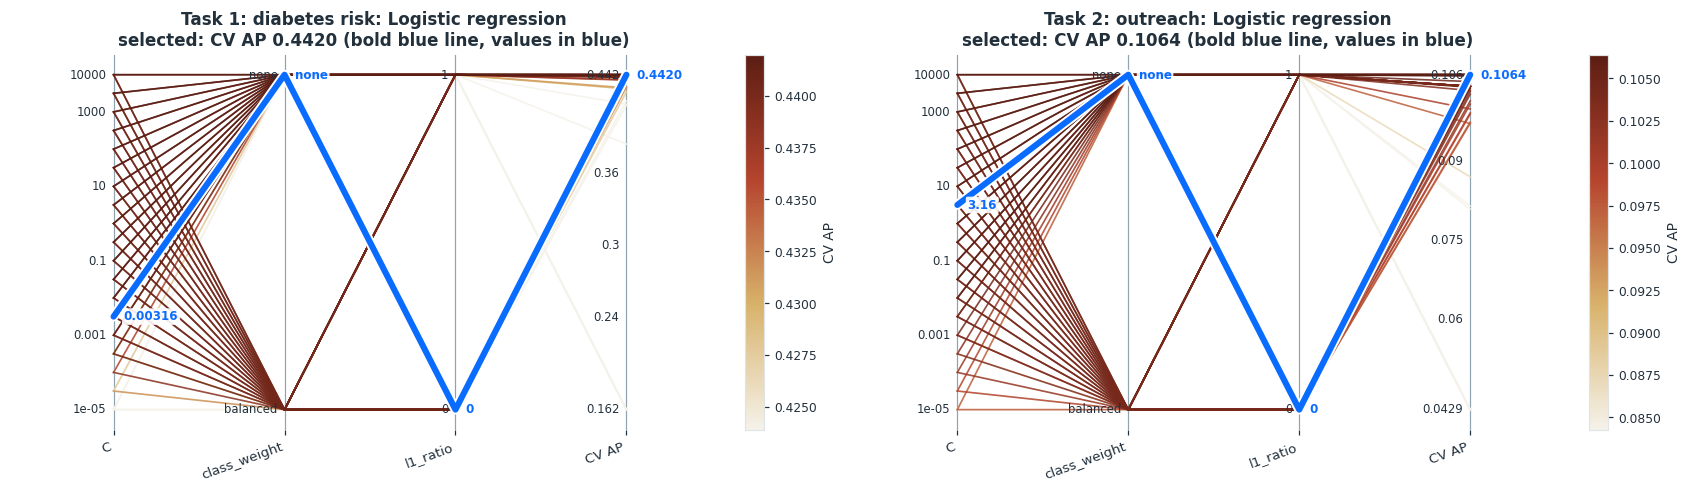

,C,class_weight,l1_ratio,CV AP,AP sd,CV AUC,fit s,candidates
Task 1: diabetes risk,0.00316,none,0,0.4420,0.0040,0.8152,0.4,76
Task 2: outreach,3.16,none,0,0.1064,0.0064,0.6900,0.2,76


In [10]:
LR_EST   = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=5_000))
LR_SPACE = {"logisticregression__C":            np.logspace(-5, 4, 19),
            "logisticregression__l1_ratio":     [0.0, 1.0],
            "logisticregression__class_weight": [None, "balanced"]}
for key in TASKS:
    experiment(key, "Logistic regression", LR_EST, LR_SPACE)
report("Logistic regression")

> **Notes (to write from the outputs above):** which settings won for each task, and whether C, the penalty or class weighting matter (the curve was flat in Lab 2).

### 5.2 Bagged GLMnet

Logistic regression with an elastic-net penalty, fit with the `saga` solver on bootstrap
samples of the training rows, with the predicted probabilities averaged. 256 candidates chosen by TPE (32 random start-up trials, then guided).

- **`C`** (1e-4 to 1e3, log scale): the inverse of the penalty strength, as above.
- **`l1_ratio`** (0 to 1): the mix of the two penalties. 0 is pure L2, 1 is pure L1, and
  values in between blend them.
- **`class_weight`** (none or balanced): as above.
- **`n_estimators`** (10, 25 or 50): how many models are averaged. More models give a steadier
  average.
- **`max_samples`** (0.2 to 1.0): the share of training rows each model is fit on. Smaller
  samples make the models differ more from each other.

In [ ]:
GLM_EST = make_pipeline(StandardScaler(), BaggingClassifier(
    LogisticRegression(solver="saga", max_iter=300, tol=1e-3), random_state=SEED, n_jobs=1))
GLM_SPACE = {"baggingclassifier__estimator__C":            loguniform(1e-4, 1e3),
             "baggingclassifier__estimator__l1_ratio":     uniform(0, 1),
             "baggingclassifier__estimator__class_weight": [None, "balanced"],
             "baggingclassifier__n_estimators":            [10, 25, 50],
             "baggingclassifier__max_samples":             uniform(0.2, 0.8)}
for key in TASKS:
    experiment(key, "Bagged GLMnet", GLM_EST, GLM_SPACE, n_iter=64, sampler="tpe")
report("Bagged GLMnet")

T1 Bagged GLMnet:   3%|▎         | 2/64 [00:19<20:16, 19.63s/trial, best_AP=0.4419]

[W 2026-10-18 18:27:04,539] Trial 2 failed with parameters: {'baggingclassifier__estimator__C': 0.12493860296459115, 'baggingclassifier__estimator__l1_ratio': 0.17451982270899358, 'baggingclassifier__estimator__class_weight': 'balanced', 'baggingclassifier__n_estimators': 25, 'baggingclassifier__max_samples': 0.4656425686465575} because of the following error: KeyboardInterrupt().
joblib.externals.loky.process_executor._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "/Users/jwkle/diabetes/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py", line 490, in _process_worker
    r = call_item()
        ^^^^^^^^^^^
  File "/Users/jwkle/diabetes/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py", line 291, in __call__
    return self.fn(*self.args, **self.kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/jwkle/diabetes/.venv/lib/python3.12/site-packages/joblib/parallel.py", line 607, in __call__
    return

T1 Bagged GLMnet:   3%|▎         | 2/64 [00:31<16:14, 15.72s/trial, best_AP=0.4419]


KeyboardInterrupt: 

> **Notes (to write from the outputs above):** whether bagging the elastic net changes anything compared with plain logistic regression.

### 5.3 Linear SVM

A full grid of 84 candidates. Squared hinge loss is solved in the primal (`dual=False`),
which fits in about a second. The SVM outputs a signed distance from its boundary rather than
a probability; §6 rescales it.

- **`C`** (1e-7 to 1e3, 21 values): the inverse of the penalty strength. Small values allow a
  wide margin with many points inside it; large values fit the training rows more tightly.
- **`penalty`** (L1 or L2): the type of penalty, as for logistic regression.
- **`class_weight`** (none or balanced): as above.

In [ ]:
SVM_EST   = make_pipeline(StandardScaler(), LinearSVC(dual=False, max_iter=10_000, random_state=SEED))
SVM_SPACE = {"linearsvc__C":            np.logspace(-7, 3, 21),
             "linearsvc__penalty":      ["l1", "l2"],
             "linearsvc__class_weight": [None, "balanced"]}
for key in TASKS:
    experiment(key, "Linear SVM", SVM_EST, SVM_SPACE)
report("Linear SVM")

> **Notes (to write from the outputs above):** the selected C and penalty for each task, and how the result compares with Lab 2.

### 5.4 Decision tree

A full grid of 256 candidates.

- **`max_depth`** (3 to 20, or unlimited): how many splits deep the tree can grow. Deeper
  trees capture more interactions but overfit more easily.
- **`min_samples_leaf`** (1 to 3,200): the fewest training rows a leaf may hold. Larger leaves
  give smoother, more stable predictions.
- **`criterion`** (gini or entropy): how the quality of a split is measured. The two usually
  choose similar splits.
- **`class_weight`** (none or balanced): as above.

In [ ]:
DT_EST   = DecisionTreeClassifier(random_state=SEED)
DT_SPACE = {"max_depth":        [3, 5, 7, 9, 12, 15, 20, None],
            "min_samples_leaf": [1, 20, 100, 200, 400, 800, 1600, 3200],
            "criterion":        ["gini", "entropy"],
            "class_weight":     [None, "balanced"]}
for key in TASKS:
    experiment(key, "Decision tree", DT_EST, DT_SPACE)
report("Decision tree")

> **Notes (to write from the outputs above):** the depth and leaf size that won, and how far the tree falls below the linear models.

### 5.5 Random forest

256 candidates chosen by TPE (32 random start-up trials, then guided).

- **`n_estimators`** (200, 300 or 500): the number of trees averaged. More trees give a
  steadier average, with diminishing returns.
- **`max_depth`** (12, 16, 24 or unlimited) and **`min_samples_leaf`** (5 to 200): how far
  each tree can grow, as for the single tree.
- **`max_features`** (3 to 18): how many features each split may choose from. Fewer features
  make the trees differ more from each other. 4 matches scikit-learn's `"sqrt"` rule for both
  tasks.
- **`max_samples`** (0.05 to 0.7): the share of training rows in each tree's bootstrap
  sample. Smaller samples train faster and also make the trees differ more.
- **`class_weight`** (none or balanced_subsample): whether the rare class is reweighted
  inside each bootstrap sample.

In [ ]:
RF_EST   = RandomForestClassifier(random_state=SEED, n_jobs=1)
RF_SPACE = {"n_estimators":     [200, 300, 500],
            "max_depth":        [12, 16, 24, None],
            "min_samples_leaf": [5, 10, 20, 50, 100, 200],
            "max_features":     [3, 4, 6, 9, 12, 15, 18],
            "max_samples":      [0.05, 0.1, 0.2, 0.4, 0.7],
            "class_weight":     [None, "balanced_subsample"]}
for key in TASKS:
    experiment(key, "Random forest", RF_EST, RF_SPACE, n_iter=128, sampler="tpe")
report("Random forest")

> **Notes (to write from the outputs above):** which hyperparameters drive the score (leaf size, features per split), and the gain over the single tree.

### 5.6 XGBoost

256 candidates chosen by TPE (32 random start-up trials, then guided).

- **`n_estimators`** (100 to 1,600) and **`learning_rate`** (0.002 to 0.3): how many trees are
  added, and how much each one corrects the trees before it. A lower rate needs more trees but
  usually generalizes better.
- **`max_depth`** (2 to 10): the size of each tree, which sets how many features can interact
  within one tree.
- **`min_child_weight`** (1 to 300): how much evidence a leaf must hold before a split is
  allowed. Larger values prune more.
- **`subsample`** (0.4 to 1.0) and **`colsample_bytree`** (0.3 to 1.0): the share of rows and
  of features each tree sees. The sampling adds randomness that guards against overfitting.
- **`reg_lambda`** (0.1 to 300): an L2 penalty on the leaf values, which shrinks each tree's
  corrections.
- **`scale_pos_weight`** (1, or the task's negatives-per-positive ratio): whether the rare
  class is reweighted, the boosting equivalent of balanced class weights.

In [ ]:
XGB_EST = XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, eval_metric="logloss")
def xgb_space(key):
    y = TASKS[key]["y_train"]
    return {"n_estimators":     [100, 200, 400, 800, 1600],
            "learning_rate":    loguniform(0.002, 0.3),
            "max_depth":        randint(2, 11),
            "min_child_weight": loguniform(1, 300),
            "subsample":        uniform(0.4, 0.6),
            "colsample_bytree": uniform(0.3, 0.7),
            "reg_lambda":       loguniform(0.1, 300),
            "scale_pos_weight": [1.0, round(float((1 - y.mean()) / y.mean()), 2)]}
for key in TASKS:
    experiment(key, "XGBoost", XGB_EST, xgb_space(key), n_iter=256, sampler="tpe")
report("XGBoost")

> **Notes (to write from the outputs above):** learning rate and depth trade-offs, and whether scale_pos_weight helps.

### 5.7 Sweep summary

The best cross-validated score of each family, side by side.

In [ ]:
BASE_MODELS = ["Logistic regression", "Bagged GLMnet", "Linear SVM", "Decision tree", "Random forest", "XGBoost"]
def best_row(k, m):
    tb = load_sweep(k, m)
    return {"CV AP": tb.loc[tb.selected, "CV AP"].iloc[0], "CV AUC": tb.loc[tb.selected, "CV AUC"].iloc[0],
            "candidates": len(tb), "mean fit s": tb["fit s"].mean()}

summary = pd.DataFrame({(t["title"], m): best_row(k, m) for k, t in TASKS.items() for m in BASE_MODELS}).T
display(summary.style.format({"CV AP": "{:.4f}", "CV AUC": "{:.4f}", "candidates": "{:.0f}",
                              "mean fit s": "{:.1f}"}))

> **Notes (to write from the outputs above):** rank the families by CV AP for each task, and note that Task 2's scores sit far lower because the outcome is rare and the file lacks the main drivers of access.

## 6. Stacked ensemble

The ensemble is a logistic regression whose inputs are the six models' scores. Its
training data must be scores the base models produced on rows they did **not** see, or the
meta-model learns to trust whichever model overfits most (an unpruned tree would look
perfect). So each tuned model is refit five times by the same 5 folds, and each training row
is scored by the fit that left it out. The meta-model is trained on those out-of-fold
scores, then applied to the validation and test sets using the base models refit on all of
`train` in §5.

Probabilities enter on the log-odds scale, so a move from 0.01 to 0.02 counts as much as
one from 0.33 to 0.50. The SVM's distance is already on a linear scale. All six inputs are
standardized, so the meta-model's coefficients are directly comparable: each is the weight
the ensemble puts on that model. `C` and class weighting are swept by the same 5-fold CV.

In [ ]:
import hashlib


def as_input(model, s):
    """Base-model score on the ensemble's input scale: log-odds for probabilities, raw for the SVM."""
    if hasattr(model, "predict_proba"):
        s = np.clip(s, 1e-6, 1 - 1e-6)
        return np.log(s / (1 - s))
    return s


def stack_inputs(key, split):
    t = TASKS[key]
    return np.column_stack([as_input(MODELS[key][m], scores(MODELS[key][m], t[f"X_{split}"])) for m in BASE_MODELS])


def oof_input(model, X, y):
    """Out-of-fold score for every training row, on the ensemble's input scale."""
    method = "predict_proba" if hasattr(model, "predict_proba") else "decision_function"
    p = cross_val_predict(clone(model), X, y, cv=CV, n_jobs=N_JOBS, method=method)
    return as_input(model, p[:, 1] if p.ndim == 2 else p)


for key, t in TASKS.items():
    path = CACHE / f"{key}_oof.joblib"
    spec = repr([(lambda tb: tb.loc[tb["selected"]].drop(columns=list(META)).to_dict("records"))(load_sweep(key, m))
                 for m in BASE_MODELS])                        # rebuild whenever a base model's winner changes
    cached = joblib.load(path) if path.exists() else None
    if isinstance(cached, dict) and cached.get("spec") == spec:
        oof = cached["oof"]
    else:
        t0 = time.perf_counter()
        oof = np.column_stack([oof_input(MODELS[key][m], t["X_train"], t["y_train"]) for m in BASE_MODELS])
        joblib.dump(dict(spec=spec, oof=oof), path)
        print(f"{t['title']:<24} out-of-fold scores in {(time.perf_counter()-t0)/60:.1f} min")
    t["oof"] = pd.DataFrame(oof, columns=BASE_MODELS, index=t["X_train"].index)
    t["oof_tag"] = f" inputs={hashlib.md5(spec.encode()).hexdigest()[:12]}"   # ties the ensemble's cache to these inputs

In [ ]:
ENS_EST   = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=5_000))
ENS_SPACE = {"logisticregression__C":            np.logspace(-4, 2, 13),
             "logisticregression__class_weight": [None, "balanced"]}

for key, t in TASKS.items():
    experiment(key, "Ensemble", ENS_EST, ENS_SPACE, X=t["oof"], tag=t["oof_tag"])
report("Ensemble")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (key, t) in zip(axes, TASKS.items()):
    w = pd.Series(MODELS[key]["Ensemble"][-1].coef_[0], index=BASE_MODELS)
    ax.barh(w.index[::-1], w.values[::-1], color=[PALETTE["pos"] if v > 0 else PALETTE["prot"] for v in w.values[::-1]],
            height=.6)
    for i, v in enumerate(w.values[::-1]):
        ax.text(v + (.03 if v >= 0 else -.03) * np.abs(w).max(), i, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color=PALETTE["ink"], lw=.8); ax.grid(axis="y", visible=False)
    ax.set_xlabel("meta-model coefficient (per 1 SD of the input score)")
    ax.set_title(f"{t['title']}: weight on each base model")
    ax.set_xlim(min(0, w.min()) * 1.35 - .05, w.max() * 1.25 + .05)
plt.tight_layout(); plt.show()

for key, t in TASKS.items():
    r = t["oof"].corr().where(~np.eye(len(BASE_MODELS), dtype=bool)).stack()
    print(f"{t['title']:<24} out-of-fold score correlations: {r.min():.2f} to {r.max():.2f}")

> **Notes (to write from the outputs above):** which base models the meta-model leans on, how correlated their scores are, and whether stacking improved on the best single model.

## 7. Threshold sweep

Each model's scores on the validation set are swept over every possible threshold, and the
one with the highest F2 is kept. The plots show precision, recall and F2 at each threshold
for each task's best model on validation F2, with the chosen threshold marked by the dotted
line. The table below gives the chosen threshold of every model. Thresholds are on each
model's own scale (probability, or the SVM's signed distance), so the **share of the
validation set flagged** is the column to compare across models: it is the share of people
who would be referred (Task 1) or contacted (Task 2).

In [ ]:
ALL_MODELS = BASE_MODELS + ["Ensemble"]


def model_scores(key, name, split):
    if name == "Ensemble":
        return scores(MODELS[key]["Ensemble"], stack_inputs(key, split))
    return scores(MODELS[key][name], TASKS[key][f"X_{split}"])


def f2_curve(y_true, s):
    """Precision, recall, F2 and share flagged at every threshold."""
    prec, rec, thr = precision_recall_curve(y_true, s)
    prec, rec = prec[:-1], rec[:-1]
    f2 = np.where(prec + rec > 0, 5 * prec * rec / (4 * prec + rec), 0)
    flagged = rec * y_true.sum() / np.where(prec > 0, prec, np.nan) / len(y_true)
    return thr, prec, rec, f2, flagged


TUNED = {}
for key, t in TASKS.items():
    TUNED[key] = {}
    for name in ALL_MODELS:
        thr, prec, rec, f2, flg = f2_curve(t["y_val"].to_numpy(), model_scores(key, name, "val"))
        i = int(np.argmax(f2))
        TUNED[key][name] = dict(threshold=thr[i], val_precision=prec[i], val_recall=rec[i],
                                val_f2=f2[i], val_flagged=flg[i])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (key, t) in zip(axes, TASKS.items()):
    best = max(TUNED[key], key=lambda m: TUNED[key][m]["val_f2"])
    s = model_scores(key, best, "val")
    thr, prec, rec, f2, _ = f2_curve(t["y_val"].to_numpy(), s)
    op = TUNED[key][best]
    proba = hasattr(MODELS[key][best], "predict_proba")

    ax.plot(thr, prec, color=PALETTE["prot"], lw=1.8, label="precision")
    ax.plot(thr, rec,  color=PALETTE["pos"],  lw=1.8, label="recall")
    ax.plot(thr, f2,   color=PALETTE["ink"],  lw=2.2, label="F2")
    ax.axvline(op["threshold"], color=PALETTE["accent"], ls=":", lw=1.6)
    ax.plot(op["threshold"], op["val_f2"], "o", color=PALETTE["accent"], ms=8)
    ax.annotate(f"threshold {op['threshold']:.3f}\nF2 {op['val_f2']:.3f}", (op["threshold"], .97),
                xytext=(6, 0), textcoords="offset points", va="top", color=PALETTE["accent"], fontsize=9)
    lo, hi = np.percentile(s, [0.5, 99.5])                    # central 99% of scores; Task 2 rarely exceeds 0.3
    ax.set_xlim(0 if proba else lo, hi); ax.set_ylim(0, 1.02)
    ax.set_xlabel("threshold (probability)" if proba else "threshold (decision score)"); ax.set_ylabel("score")
    ax.set_title(f"{t['title']}: {best} (validation)"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

thr_table = pd.concat({TASKS[k]["title"]: pd.DataFrame(v).T for k, v in TUNED.items()})
thr_table["val_flagged"] *= 100
display(thr_table.rename(columns={"val_flagged": "val flagged %"}).style.format("{:.4f}")
        .format("{:.1f}", subset=["val flagged %"]))

> **Notes (to write from the outputs above):** how many people each model flags at its best-F2 threshold, and how flat the F2 curves are near their peak.

## 8. Results

Every model is scored once on its task's test set at the threshold chosen on validation.
The tables are ranked by test F2 and include the full confusion matrix: true positives
(TP), false positives (FP), false negatives (FN) and true negatives (TN). AP and ROC-AUC
do not depend on the threshold and are shown for reference.

In [ ]:
RESULTS = {}
for key, t in TASKS.items():
    y = t["y_test"].to_numpy()
    rows = []
    for name in ALL_MODELS:
        s = model_scores(key, name, "test")
        pred = s >= TUNED[key][name]["threshold"]
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        rows.append({"model": name, "val F2": TUNED[key][name]["val_f2"],
                     "precision": precision_score(y, pred), "recall": recall_score(y, pred),
                     "F2": fbeta_score(y, pred, beta=2), "AP": average_precision_score(y, s),
                     "AUC": roc_auc_score(y, s), "flagged %": 100 * pred.mean(),
                     "TP": tp, "FP": fp, "FN": fn, "TN": tn})
    r = pd.DataFrame(rows).sort_values("F2", ascending=False).reset_index(drop=True)
    r.index = pd.Index(range(1, len(r) + 1), name="rank")
    RESULTS[key] = r

FMT = {c: "{:.4f}" for c in ["val F2", "precision", "recall", "F2", "AP", "AUC"]}
FMT |= {"flagged %": "{:.1f}"} | {c: "{:,d}" for c in ["TP", "FP", "FN", "TN"]}

### 8.1 Task 1: diabetes risk

In [ ]:
def show_results(key):
    t = TASKS[key]
    print(f"{t['title']}: test set, {len(t['y_test']):,} respondents, {int(t['y_test'].sum()):,} positive "
          f"({100*t['y_test'].mean():.2f}%)")
    display(RESULTS[key].style.format(FMT).background_gradient(cmap=SEQ, subset=["F2"]))

    fig, axes = plt.subplots(2, 4, figsize=(15, 7.2))
    for ax, (_, row) in zip(axes.flat, RESULTS[key].iterrows()):
        cm = np.array([[row.TN, row.FP], [row.FN, row.TP]])
        sns.heatmap(cm, annot=True, fmt=",d", cmap=SEQ, cbar=False, ax=ax, linewidths=.6,
                    linecolor="white", annot_kws={"fontsize": 11},
                    xticklabels=t["labels"], yticklabels=t["labels"])
        ax.set_xlabel("predicted"); ax.set_ylabel("actual")
        ax.set_title(f"{row.model}\nF2 {row.F2:.3f} · recall {row.recall:.3f} · precision {row.precision:.3f}",
                     fontsize=9.8)
    axes.flat[-1].axis("off")
    fig.suptitle(f"{t['title']}: test-set confusion matrices, ranked by F2", fontweight="bold")
    plt.tight_layout(); plt.show()

show_results("T1")

> **Notes (to write from the outputs above):** the best model on test F2, its recall and precision in counts, and whether validation and test agree.

### 8.2 Task 2: outreach

In [ ]:
show_results("T2")

> **Notes (to write from the outputs above):** the best outreach model, how many unscreened people it finds and at what contact cost, and how this compares with Task 1.

## 9. Who is high-risk and unscreened?

The Task 1 model never saw the 9,470 respondents without a cholesterol check in five years
(§3 withheld them), so its scores on them are out-of-sample predictions. Scoring them and
keeping the ones it flags who are *not* diagnosed gives the group the screening programme
is for: people whose profile looks like diabetes, who have no diagnosis, and who are not
seeing a doctor. Three nested groups are compared:

| group | definition |
|---|---|
| **General population** | every respondent in the file |
| **Unscreened** | `CholCheck` = 0 |
| **High-risk, unscreened** | unscreened, `Diabetes_binary` = 0, and flagged by the best Task 1 model at its §7 threshold |

The middle group separates what being unscreened looks like from what being high-risk *and*
unscreened looks like. The comparison uses the standardized mean difference (SMD): the gap
between a group's mean and the population mean, in population standard deviations. An SMD
beyond ±0.2 is usually read as a meaningful difference, beyond ±0.5 as a large one.

In [ ]:
from sklearn.isotonic import IsotonicRegression


def score_rows(key, name, X):
    """Scores from one of a task's models for any frame with that task's features."""
    if name == "Ensemble":
        X = np.column_stack([as_input(MODELS[key][m], scores(MODELS[key][m], X)) for m in BASE_MODELS])
    return scores(MODELS[key][name], X)


T1_BEST    = RESULTS["T1"].loc[1, "model"]
unscreened = df.index[df.CholCheck.eq(0)]
risk = pd.Series(score_rows("T1", T1_BEST, df.loc[unscreened, T1_FEATURES].astype(float)), index=unscreened)
flag = risk >= TUNED["T1"][T1_BEST]["threshold"]

GROUPS = {
    "General population":    df.index,
    "Unscreened":            unscreened,
    "High-risk, unscreened": risk.index[flag & df.loc[unscreened, "Diabetes_binary"].eq(0)],
}

# Scores are not all probabilities (and class weighting skews the ones that are), so an isotonic
# map fitted on the validation set turns them into calibrated probabilities for the expected count.
calib = IsotonicRegression(out_of_bounds="clip").fit(model_scores("T1", T1_BEST, "val"), TASKS["T1"]["y_val"])
expected, observed = calib.predict(risk).sum(), df.loc[unscreened, "Diabetes_binary"].sum()

sizes = pd.DataFrame({
    "respondents": {g: len(ix) for g, ix in GROUPS.items()},
    "share of file %": {g: 100 * len(ix) / len(df) for g, ix in GROUPS.items()},
    "diagnosed %": {g: 100 * df.loc[ix, "Diabetes_binary"].mean() for g, ix in GROUPS.items()},
})
display(sizes.style.format({"respondents": "{:,d}", "share of file %": "{:.2f}", "diagnosed %": "{:.1f}"}))
print(f"Task 1 model: {T1_BEST}. It flags {100*flag.mean():.1f}% of the unscreened.")
print(f"Among the unscreened it expects {expected:,.0f} diagnoses; {observed:,d} are recorded "
      f"({100*observed/expected:.0f}% of expected).")

In [ ]:
BINARY = [c for c in BASE if df[c].nunique() == 2]
means  = pd.DataFrame({g: df.loc[ix, BASE].mean() for g, ix in GROUPS.items()})
smd    = means.drop(columns="General population").sub(means["General population"], axis=0).div(df[BASE].std(), axis=0)

shown = means.copy()
shown.loc[BINARY] *= 100                                    # binary features read as prevalence %
PROFILE = pd.concat([shown, smd.add_prefix("SMD: ")], axis=1)
PROFILE.insert(0, "unit", np.where(PROFILE.index.isin(BINARY), "%", "mean"))
PROFILE = PROFILE.reindex(smd["High-risk, unscreened"].abs().sort_values(ascending=False).index)

DIV = sns.blend_palette([PALETTE["prot"], "#f4f4f2", PALETTE["pos"]], as_cmap=True)
lim = smd.abs().max().max()
display(PROFILE.style.format("{:.1f}", subset=list(GROUPS)).format("{:+.2f}", subset=list(smd.add_prefix("SMD: ")))
        .background_gradient(cmap=DIV, vmin=-lim, vmax=lim, subset=list(smd.add_prefix("SMD: "))))

In [ ]:
order = smd["High-risk, unscreened"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.hlines(y, smd.loc[order, "Unscreened"], smd.loc[order, "High-risk, unscreened"], color=PALETTE["grid"], lw=2, zorder=1)
for g, color in [("Unscreened", PALETTE["neg"]), ("High-risk, unscreened", PALETTE["pos"])]:
    ax.plot(smd.loc[order, g], y, "o", color=color, ms=8, mec="white", mew=1.2, label=g, zorder=3)
ax.axvline(0, color=PALETTE["ink"], lw=.8)
for v in (-.2, .2):
    ax.axvline(v, color=PALETTE["grid"], lw=1, ls="--")
ax.set_yticks(y, order); ax.grid(axis="y", visible=False)
ax.set_xlabel("standardized mean difference from the general population")
ax.set_title("How the unscreened differ from the general population")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

LEVELS = {
    "Age":       ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54", "55–59", "60–64",
                  "65–69", "70–74", "75–79", "80+"],
    "Income":    ["<$10k", "<$15k", "<$20k", "<$25k", "<$35k", "<$50k", "<$75k", "$75k+"],
    "Education": ["none", "elementary", "some HS", "HS grad", "some college", "college grad"],
    "GenHlth":   ["excellent", "very good", "good", "fair", "poor"],
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[13, 8, 6, 5]))
for ax, (col, labels) in zip(axes, LEVELS.items()):
    x = np.arange(1, len(labels) + 1)
    for dx, (g, color) in zip((-.2, .2), [("General population", PALETTE["neg"]), ("High-risk, unscreened", PALETTE["pos"])]):
        share = df.loc[GROUPS[g], col].value_counts(normalize=True).reindex(x, fill_value=0)
        ax.bar(x + dx, 100 * share, width=.38, color=color, label=g)
    ax.set_xticks(x, labels, rotation=55, ha="right", fontsize=8.5); ax.grid(axis="x", visible=False)
    ax.set_title(col)
axes[0].set_ylabel("% of group"); axes[0].legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

The Task 1 ensemble flags 20% of the unscreened. Removing the few who are already diagnosed
leaves **1,667 high-risk, unscreened respondents**, 0.66% of the file. The model also
reproduces Lab 1's finding without being built for it: it expects about 786 diagnoses among
the unscreened, and 303 are recorded, **39% of expected**. Roughly 480 cases are missing
from this group alone.

**The unscreened as a whole are younger and healthier than average.** They are 1.4 age
bands younger, report better general health, and are less often told they have high blood
pressure or cholesterol. Their one large difference from the population is access: 82% have
any health coverage against 95%, and twice as many skipped a doctor because of cost.

**The high-risk subgroup looks very different.** Their age is close to the population's
(peaking at 55–64), but almost every other feature points the wrong way:

- **Access is worst here.** 79% have coverage and 27% skipped a doctor because of cost,
  more than three times the population rate (8%). These are the two largest gaps in the
  profile.
- **Poorer and less educated.** The share earning over $75k is a third of the population's
  (12% against 36%), and 24% are college graduates against 42%.
- **Sicker by their own account.** 36% rate their health fair or poor against 17%. They
  report more days of poor physical and mental health, and 28% have difficulty walking.
- **Heavier and less active.** Mean BMI is 31.3 against 28.4, and 58% exercise against 76%.
  58% have smoked against 44%.
- **Slightly more often male.** 53% against 44%.

Put simply, the high-risk unscreened are middle-aged, low-income adults with poor health
and poor access, many of them uninsured or unable to afford a visit. Outreach to this group
should lead with cost (free or low-cost screening) rather than awareness. Their own health
ratings suggest many already know something is wrong.

Two caveats:

- **The diagnoses in the profile are under-counted.** High blood pressure, high cholesterol,
  heart disease and stroke are things a doctor tells you (§2). This group sees doctors least,
  so its 53% high blood pressure and 51% high cholesterol are lower bounds, and its clinical
  risk is probably higher than the table shows.
- **"General population" means respondents.** The file is unweighted BRFSS data, so the
  shares describe the survey sample, not U.S. adults.

## 10. Conclusion

> **Notes (to write once the results are in):** the best model for each task and its test F2;
> whether the flexible models beat the linear ones; what the ensemble added; and how the two
> scores would combine into an outreach list (high risk *and* likely unscreened).

## 11. External validation across survey years

The models were trained and tuned on 2015 only. Each odd BRFSS year (the years that ask the blood-pressure, cholesterol and fruit/veg questions) is rebuilt the way the Kaggle file was built from 2015: the same recipe, same drop rule, same recodes (downloaded from the Hugging Face dataset [`LoneWolfgang/brfss-llcp`](https://huggingface.co/datasets/LoneWolfgang/brfss-llcp), BRFSS parsed to parquet; the drop rule is applied here). Every model then scores every year unchanged. 2015 itself is shown on its test split, since the rest of 2015 trained the models.

In [ ]:
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq

HF_REPO   = "LoneWolfgang/brfss-llcp"      # BRFSS parsed to parquet: one file per survey year, every row
ODD_YEARS = list(range(2013, 2026, 2))      # BP, cholesterol and fruit/veg are asked in odd years only

# Kaggle column <- (the raw variable's name in each year, first one present is used;
#                   recode to the Kaggle values; don't-know / refused codes, whose rows Kaggle drops)
RECIPE = {
    "Diabetes_012":         (["DIABETE3", "DIABETE4"], {1: 2, 2: 0, 3: 0, 4: 1}, {7, 9}),
    "HighBP":               (["_RFHYPE5", "_RFHYPE6"], {1: 0, 2: 1}, {9}),
    "HighChol":             (["TOLDHI2", "TOLDHI3"], {2: 0}, {7, 9}),
    "CholCheck":            (["_CHOLCHK", "_CHOLCH1", "_CHOLCH2", "_CHOLCH3"], {2: 0, 3: 0}, {9}),
    "BMI":                  (["_BMI5"], {}, set()),
    "Smoker":               (["SMOKE100"], {2: 0}, {7, 9}),
    "Stroke":               (["CVDSTRK3"], {2: 0}, {7, 9}),
    "HeartDiseaseorAttack": (["_MICHD"], {2: 0}, set()),
    "PhysActivity":         (["_TOTINDA"], {2: 0}, {9}),
    "Fruits":               (["_FRTLT1", "_FRTLT1A"], {2: 0}, {9}),
    "Veggies":              (["_VEGLT1", "_VEGLT1A"], {2: 0}, {9}),
    "HvyAlcoholConsump":    (["_RFDRHV4", "_RFDRHV5", "_RFDRHV6", "_RFDRHV7", "_RFDRHV8", "_RFDRHV9"], {1: 0, 2: 1}, {9}),
    "AnyHealthcare":        (["HLTHPLN1", "_HLTHPLN", "_HLTHPL1", "_HLTHPL2"], {2: 0}, {7, 9}),
    "NoDocbcCost":          (["MEDCOST", "MEDCOST1"], {2: 0}, {7, 9}),
    "GenHlth":              (["GENHLTH"], {}, {7, 9}),
    "MentHlth":             (["MENTHLTH"], {88: 0}, {77, 99}),
    "PhysHlth":             (["PHYSHLTH"], {88: 0}, {77, 99}),
    "DiffWalk":             (["DIFFWALK"], {2: 0}, {7, 9}),
    "Sex":                  (["SEX", "SEX1", "SEXVAR"], {2: 0}, set()),
    "Age":                  (["_AGEG5YR"], {}, {14}),
    "Education":            (["EDUCA"], {}, {9}),
    "Income":               (["INCOME2", "INCOME3"], {}, {77, 99}),
}
# later names that code don't-know / refused differently from the 2015 variable
DROP_CODES = {"SEX": {9}, "SEX1": {7, 9}, "_HLTHPLN": {9}, "_HLTHPL1": {9}, "_HLTHPL2": {9}}


def kaggle_frame(year):
    """One survey year as the Kaggle file: rows with a blank or a don't-know / refused answer in
    any recipe variable dropped, the rest recoded the 2015 way."""
    path   = hf_hub_download(HF_REPO, f"data/LLCP{year}.parquet", repo_type="dataset")   # cached after the first call
    have   = set(pq.read_schema(path).names)
    source = {col: next((v for v in names if v in have), None) for col, (names, _, _) in RECIPE.items()}
    extra  = ["CVDINFR4", "CVDCRHD4"] if source["HeartDiseaseorAttack"] is None else []
    d = pd.read_parquet(path, columns=[v for v in source.values() if v] + extra)
    drop = np.zeros(len(d), dtype=bool)
    for col, v in source.items():
        if v:
            drop |= (d[v].isna() | d[v].isin(DROP_CODES.get(v, RECIPE[col][2]))).to_numpy(dtype=bool)
    d = d.loc[~drop].astype(float)
    if extra:      # 2013 has no _MICHD: build it as CDC does (1 heart attack or CHD, 2 neither), drop the unknowns
        d["_MICHD"] = np.select([d.CVDINFR4.eq(1) | d.CVDCRHD4.eq(1), d.CVDINFR4.eq(2) & d.CVDCRHD4.eq(2)],
                                [1.0, 2.0], np.nan)
        d, source["HeartDiseaseorAttack"] = d.dropna(subset=["_MICHD"]), "_MICHD"
    out = pd.DataFrame({col: d[source[col]].replace(RECIPE[col][1]) if source[col] else np.nan for col in RECIPE},
                       index=d.index)
    out["BMI"] = (out["BMI"] / 100).round()            # _BMI5 has 2 implied decimals
    out["Income"] = out["Income"].clip(upper=8)         # INCOME3 (2021+) splits the top band, $75k+, into codes 8-11
    return out


def year_frame(year):
    """§1 and §3 applied to one year, centered on the 2015 means so the models see the same scale."""
    k = kaggle_frame(year)
    k["Diabetes_binary"] = (k["Diabetes_012"] > 0).astype(int)
    k["NoCheck"] = (1 - k["CholCheck"]).astype(int)
    k["BMI"] = np.minimum(k["BMI"], 70)
    for col in ["Age", "Income"]:
        k[f"{col}_sq"] = (k[col] - raw[col].mean()) ** 2
    return k


check = kaggle_frame(2015)
assert np.array_equal(check[BASE].to_numpy(), raw[BASE].to_numpy()), "2015 rebuilt from parquet differs from the CSV"

ext_rows = []
for year in ODD_YEARS:
    k = year_frame(year)
    for key, t in TASKS.items():
        if year == 2015:                        # the other 85% of 2015 trained and tuned the models
            X, y = t["X_test"], t["y_test"]
        else:
            d = k.loc[k.CholCheck.eq(1) if key == "T1" else k.Diabetes_binary.eq(0)]
            X, y = d[t["features"]].astype(float), d[t["outcome"]].astype(int)
        filled = [c for c in t["features"] if X[c].isna().all()]
        X = X.fillna(t["X_train"].mean())       # 2023 did not ask the fruit/veg questions: fill with the 2015 mean
        for name in ALL_MODELS:
            ext_rows.append({"year": year, "task": t["title"], "model": name, "rows": len(y),
                             "positive %": 100 * y.mean(), "AUC": roc_auc_score(y, score_rows(key, name, X)),
                             "filled": ", ".join(filled)})
EXT = pd.DataFrame(ext_rows)

best = {t["title"]: RESULTS[k].loc[1, "model"] for k, t in TASKS.items()}       # each task's first-ranked model on test F2
fig, ax = plt.subplots(figsize=(10, 4.6))
for title, color in zip(best, [PALETTE["pos"], PALETTE["prot"]]):
    e = EXT[EXT.task == title]
    for name, g in e.groupby("model"):
        if name != best[title]:
            ax.plot(g.year, g.AUC, color=color, lw=0.8, alpha=0.3)
    b = e[e.model == best[title]]
    ax.plot(b.year, b.AUC, "o-", color=color, lw=2.2, ms=6, label=f"{title} ({best[title]})")
    for _, r in b.iterrows():
        ax.annotate(f"{r.AUC:.3f}", (r.year, r.AUC), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8.5, color=color)
lo = EXT.AUC.min() - 0.03                        # room under the lowest line for the notes
ax.set_ylim(lo, EXT.AUC.max() + 0.015)
ax.axvspan(2014, 2016, color=PALETTE["grid"], alpha=0.5, lw=0)
ax.text(2015, lo, "2015: test split\n(training year)", ha="center", va="bottom", fontsize=8.5)
for year in EXT.loc[EXT.filled.ne(""), "year"].unique():
    ax.text(year, lo, "fruit/veg not asked,\nfilled with 2015 mean", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(ODD_YEARS); ax.set_xlabel("BRFSS survey year"); ax.set_ylabel("ROC-AUC")
ax.set_title("External validation: models trained on 2015, scored on every odd year")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2,
          title="bold: first-ranked model on test F2; thin: the others", title_fontsize=8.5)
plt.tight_layout(); plt.show()

display(EXT.pivot_table(index="model", columns=["task", "year"], values="AUC").loc[ALL_MODELS]
        .style.format("{:.4f}").background_gradient(cmap=SEQ, axis=None))
sizes = EXT.drop_duplicates(["year", "task"]).pivot_table(index="task", columns="year", values=["rows", "positive %"])
display(sizes.style.format({c: "{:,.0f}" if c[0] == "rows" else "{:.2f}" for c in sizes.columns}))